
# Eigenvalue problems
.. index:: Equations; Eigenvalue problems

.. sectionauthor:: contribution by Philip Herbert <P.Herbert@hw.ac.uk>

We use Dune and SciPy to compute the Eigenvalues and Eigenfunctions of the Laplace operator.

## Eigenvalues of the Neumann Laplacian

We first consider the simple problem that
$(u,\lambda)\in H^1(\Omega)\times{\mathbb{R}}$ satisfy
\begin{align*}
-\Delta u &= \lambda u  && \text{in } \Omega\\
\partial_\nu u &= 0     && \text{on } \partial \Omega
\end{align*}
As standard, we begin by importing ufl.
In addition, we import alugrid and consider the domain $[0,1]^2$ and refine:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ufl import *
from dune.alugrid import aluSimplexGrid
vertices = np.array( [(0,0), (1,0), (1,1), (0,1),(0.5,0.5)] )
triangles = np.array( [(0,1,4), (1,2,4), (2,4,3), (3,4,0)] )
gridView = aluSimplexGrid({"vertices": vertices, "simplices": triangles})
gridView.hierarchicalGrid.globalRefine(4)

Introduce the space and test functions:

In [2]:
from dune.fem.space import lagrange
space = lagrange(gridView, order=1)
u = TrialFunction(space)
v = TestFunction(space)

In the generalised eigenvalue problem which will be used for finite elements,
given matrices $A, M \in \mathbb{R}^{N\times N}$,
we are interested in finding pairs $(X,\lambda) \in \mathbb{R}^N \times \mathbb{R}$ such that
$$ A X = \lambda M X$$

as such, we wish to set up the finite element matrices which correspond to the problem outlined.
That is, $A$ is the stiffness matrix, $M$ the mass matrix, and $X$ will be the degrees of freedom vector.
We now construct the operators

In [3]:
from dune.fem.operator import galerkin
LHSOp = galerkin([inner(grad(u),grad(v))*dx])
RHSOp = galerkin([inner(u,v)*dx])

It is now useful to convert these into matrices, this is done with the function \emph{linear}.
For convenience we will convert them to numpy matrices

In [4]:
from dune.fem.operator import linear
A = linear(LHSOp).as_numpy
M = linear(RHSOp).as_numpy

We use scipy to solve the eigen-problem, however first we must choose how many to find

In [5]:
from scipy.sparse.linalg import eigs
num_sols = 10
eigvals, eigvecs = eigs(A, M = M, sigma = 0, k = num_sols)

sigma = 0 is used to find eigenvalues near 0, using shift-invert mode,
see [scipy.sparse.linalg.eigs](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigs.html).
For more complex problems it may be desirable to use slepc4py.
Let us compare the computed eigenvalues with known eigenvalues.

In [6]:
eigvals.real

array([-8.82627305e-15,  1.98023169e+01,  9.88689269e+00,  9.88689269e+00,
        3.98595797e+01,  3.98565801e+01,  4.98791485e+01,  4.98791485e+01,
        7.99664942e+01,  9.06848813e+01])

In [7]:
import math
pairs = [ n**2 + m**2 for n in range(num_sols) for m in range(num_sols)]
pairs.sort()
reference_eigvals = [math.pi**2 * pair for pair in pairs[:num_sols] ]
reference_eigvals

[0.0,
 9.869604401089358,
 9.869604401089358,
 19.739208802178716,
 39.47841760435743,
 39.47841760435743,
 49.34802200544679,
 49.34802200544679,
 78.95683520871486,
 88.82643960980423]

We now want to assemble a list of finite element functions and distribute the contents of
`eigvecs` into it.

In [8]:
solutions = [space.function(name = "eigenvalue"+str(i)) for i in range(num_sols)]
for k in range(num_sols):
    solutions[k].as_numpy[:] = eigvecs[:,k].real

Let us note that we have chosen a symmetric problem therefore the solutions are real.

The eigenvectors may now be plotted using vtk files or matplotlib

/home/robertk/work/Dune/testing/tutorial/dune-fem/build-cmake/python/dune/fem/plotting.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


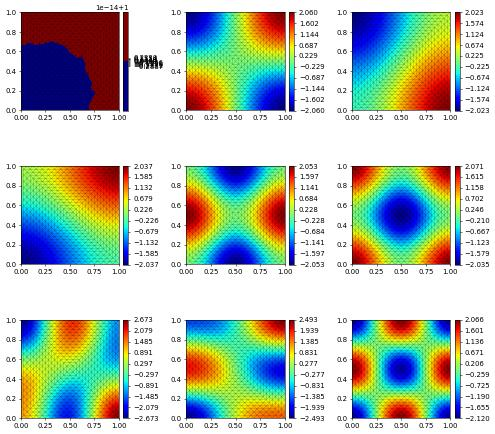

In [9]:
# gridView.writeVTK( "Neumann_Eigenvalues", pointdata = solutions )
rows, cols = num_sols//3, 3
fig, axs = plt.subplots(rows, cols, figsize=(10,10))
for k in range(rows):
    for l in range(cols):
        if k*cols+l < len(solutions):
            solutions[k*cols+l].plot( figure=(fig, axs[k][l]) )

## Dirichlet Eigenvalue problem

The calculation for the Dirichlet Eigenvalues is a little more intricate.
This is because when we adjust the LHS matrix and RHS matrix for the boundary conditions, the RHS matrix needs to be treated slightly different.
To begin, let us remind ourselves of the problem: find $(u,\lambda)\in H^1(\Omega)\times \mathbb{R}$ satisfy
\begin{align*}
-\Delta u &= \lambda u && \text{in } \Omega\\
u &= 0                 && \text{on } \partial \Omega
\end{align*}

For the moment, let us set up the new operators and save the original
mass matrix for later convenience:

In [10]:
from dune.ufl import DirichletBC
dbc = DirichletBC(space,0)
LHSOp = galerkin([inner(grad(u),grad(v))*dx, dbc])
RHSOp = galerkin([inner(u,v)*dx, dbc])
MassMatrix = M

The stiffness matrix can be setup as done previously. Note that the
Dirichlet constraints are applied by changing the corresponding rows to
unit vectors.

In [11]:
A = linear(LHSOp).as_numpy

For the mass matrix we need the diagonal entries associated with
the Dirichlet degrees of freedom to be $0$ instead of $1$. We describe
two approaches for achieving this.

Firstly we can introduce a dummy zero operator `RHSOpPerturbation` which will provide a matrix
which is the identity matrix on the boundary vertices and zero otherwise.
Since the mass matrix also has this identity sub-matrix subtracting the
two matrices achieves the desired outcome.

In [12]:
from dune.ufl import Constant
RHSOpPerturbation = galerkin([Constant(0)*inner(u,v)*dx, dbc])
M = linear(RHSOp).as_numpy - linear(RHSOpPerturbation).as_numpy

.. index::
   triple: Boundary; Dirichlet; Degrees of Freedom

The second approach makes the desired change directly on the SciPy matrix.
We first extract the
[indices of the Dirichlet dofs](boundary_nb.ipynb#Accessing-the-Dirichlet-degrees-of-freedom)
and use those indices to setup a diagonal matrix $D$ similar to the first approach.
We could now subtract the two matrices as before but instead we multiply
$M$ with $D$ from both sides to change both rows and columns in $M$ to zero.

In [13]:
import scipy.sparse as sps
import scipy.linalg as linalg
M = linear(RHSOp).as_numpy
dirichlet_zero_dofs = [i for i,b in enumerate(RHSOp.dirichletBlocks) if b[0]==1]
N = M.shape[1]
chi_interior = np.ones(N)
chi_interior[dirichlet_zero_dofs] = 0.0
D = sps.spdiags(chi_interior, [0], N, N).tocsr()
M = D * M * D

From now, besides the name of the file we plot our VTK files into, all of the steps are repeated.
It is important to note that the eigenfunctions will not be normalised as expected (e.g. with $\int_\Omega u^2 =1$).
This is because of the modification on the boundary of the matrix $M$.
This can be fixed by multiplying each vector by the appropriate value.
For this problem it is not necessary to perform, but we include it for convenience.

In [14]:
eigvals, eigvecs = eigs(A, M = M, sigma = 0, k = num_sols)
solutions = [space.function(name = "eigenvalue"+str(i)) for i in range(num_sols)]

Let us again compare the computed eigenvalues with known eigenvalues.

In [15]:
eigvals.real

array([ 19.80231965,  49.68601932,  49.68601932,  79.97204677,
       100.31181665, 100.33277311, 131.14538363, 131.14538363,
       172.34815035, 172.34815035])

In [16]:
import math
pairs = [ n**2 + m**2 for n in range(1,num_sols+1) for m in range(1,num_sols+1)]
pairs.sort()
reference_eigvals = [math.pi**2 * pair for pair in pairs[:num_sols] ]
reference_eigvals

[19.739208802178716,
 49.34802200544679,
 49.34802200544679,
 78.95683520871486,
 98.69604401089359,
 98.69604401089359,
 128.30485721416164,
 128.30485721416164,
 167.7832748185191,
 167.7832748185191]


We include numpy so that perform the 'renormalisation' required.
It is often unnecessary to do so as this will not be the dominating contribution to the error.

/home/robertk/work/Dune/testing/tutorial/dune-fem/build-cmake/python/dune/fem/plotting.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


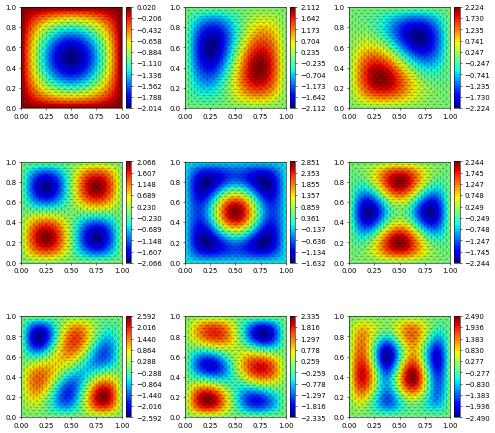

In [17]:
import numpy
for k in range(num_sols):
    solutions[k].as_numpy[:] = eigvecs[:,k].real
    L2Value = sqrt(numpy.dot(solutions[k].as_numpy, MassMatrix*solutions[k].as_numpy))
    solutions[k].as_numpy[:]/=L2Value
# gridView.writeVTK( "Dirichlet_Eigenvalues", pointdata = solutions )
rows, cols = num_sols//3, 3
fig, axs = plt.subplots(rows, cols, figsize=(10,10))
for k in range(rows):
    for l in range(cols):
        if k*cols+l < len(solutions):
            solutions[k*cols+l].plot( figure=(fig, axs[k][l]) )